# Exploración de Bank Marketing y validación de calidad
Ejecutar todas las celdas en orden desde un kernel nuevo. Primero se busca `data/bank-full.csv`, recuperable con `dvc pull`. Si no existe, se descarga el archivo oficial de UCI y se comprueban su tamaño y MD5 contra `data/bank-full.csv.dvc` antes de leerlo. Una discrepancia detiene la ejecución.

Las cuatro gráficas del informe se regeneran en `docs/figuras/`. Las comprobaciones de conteos corresponden a esta versión concreta del dataset; si se versionan nuevos datos, deben revisarse sus valores esperados.

In [1]:
import pandas as pd
import requests
import zipfile
import io
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import gaussian_kde
import hashlib
import re

In [2]:
# Localizar el repositorio y leer la referencia versionada por DVC.
# En Colab: abrir este notebook desde una copia clonada del repositorio,
# o situar el directorio de trabajo dentro de esa copia.
candidatos = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "priorizacion-clientes-cdt"]
raiz_proyecto = next(
    (p for p in candidatos if (p / "data/bank-full.csv.dvc").is_file()), None
)
if raiz_proyecto is None:
    raise FileNotFoundError("No se encontró data/bank-full.csv.dvc. Clone el repositorio y ejecute desde su carpeta.")

referencia_dvc = raiz_proyecto / "data/bank-full.csv.dvc"
metadatos_dvc = referencia_dvc.read_text(encoding="utf-8-sig")
coincidencia_hash = re.search(r"^\s*-?\s*md5:\s*([a-f0-9]{32})\s*$", metadatos_dvc, re.MULTILINE)
coincidencia_size = re.search(r"^\s*size:\s*(\d+)\s*$", metadatos_dvc, re.MULTILINE)
if coincidencia_hash is None or coincidencia_size is None:
    raise ValueError("La referencia DVC debe declarar md5 y size para verificar el dataset.")
md5_esperado = coincidencia_hash.group(1)
tamano_esperado = int(coincidencia_size.group(1))
ruta_dataset = raiz_proyecto / "data/bank-full.csv"
ruta_figuras = raiz_proyecto / "docs/figuras"
ruta_figuras.mkdir(parents=True, exist_ok=True)

In [3]:
# Buscar el CSV dentro del ZIP principal o de los ZIP internos
def buscar_csv(contenido, nombres_preferidos):
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        archivos = z.namelist()

        # Buscar primero bank-full.csv y luego bank.csv
        for nombre_objetivo in nombres_preferidos:
            for nombre in archivos:
                if nombre.lower().endswith(nombre_objetivo.lower()):
                    datos = z.read(nombre)
                    return datos, nombre

        # Si hay ZIP internos, buscar también dentro de ellos
        for nombre in archivos:
            if nombre.lower().endswith(".zip"):
                resultado = buscar_csv(
                    z.read(nombre),
                    nombres_preferidos
                )
                if resultado is not None:
                    return resultado

    return None

# Preferir el archivo recuperado mediante dvc pull. Si no está disponible,
# descargar UCI y exigir que coincida exactamente con la versión de DVC.
if ruta_dataset.is_file():
    contenido_csv = ruta_dataset.read_bytes()
    archivo_encontrado = str(ruta_dataset.relative_to(raiz_proyecto))
    origen_dataset = "Archivo local versionado con DVC"
else:
    url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    resultado = buscar_csv(response.content, ["bank-full.csv"])
    if resultado is None:
        raise FileNotFoundError("No se encontró bank-full.csv en el ZIP oficial de UCI.")
    contenido_csv, archivo_encontrado = resultado
    origen_dataset = "Descarga oficial UCI verificada contra DVC"

md5_observado = hashlib.md5(contenido_csv).hexdigest()
if md5_observado != md5_esperado or len(contenido_csv) != tamano_esperado:
    raise ValueError(
        f"El dataset no coincide con DVC: md5={md5_observado}, bytes={len(contenido_csv)}. "
        "Recupere la versión correcta mediante dvc pull."
    )
if not ruta_dataset.is_file():
    ruta_dataset.parent.mkdir(parents=True, exist_ok=True)
    ruta_dataset.write_bytes(contenido_csv)
print("Origen:", origen_dataset)
print("Integridad DVC verificada; MD5:", md5_observado)

# El CSV de UCI usa punto y coma como separador
df = pd.read_csv(
    io.BytesIO(contenido_csv),
    sep=";",
    na_values=["NA", ""]
)

print("Archivo cargado:", archivo_encontrado)
print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 10 filas:")
display(df.head(10))

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo_de_dato"))

print("\nValores faltantes por columna:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("valores_faltantes")
)

print("\nDistribución de la variable objetivo (y):")
display(df["y"].value_counts(dropna=False).to_frame("cantidad"))

print("\nPorcentaje de cada clase:")
display(
    (df["y"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("porcentaje")
)

Origen: Archivo local versionado con DVC
Integridad DVC verificada; MD5: e6b0ca77f3f200ec5428e04dd104da53
Archivo cargado: data/bank-full.csv
Dimensiones: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 10 filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no



Tipos de datos:


,tipo_de_dato
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Valores faltantes por columna:


,valores_faltantes
age,0
day,0
poutcome,0
previous,0
pdays,0
campaign,0
duration,0
month,0
contact,0
job,0



Distribución de la variable objetivo (y):


,cantidad
y,
no,39922
yes,5289



Porcentaje de cada clase:


,porcentaje
y,
no,88.3
yes,11.7


In [4]:
# Normalizar cadenas vacías como valores ausentes reales
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Dimensiones:", df.shape)
print("\nColumnas:")
print(df.columns.tolist())

print("\nPrimeras 5 filas:")
display(df.head())

print("\nTipos de datos:")
display(df.dtypes.to_frame("tipo"))

print("\nDuplicados exactos:", df.duplicated().sum())

Dimensiones: (45211, 17)

Columnas:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Primeras 5 filas:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



Tipos de datos:


,tipo
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Duplicados exactos: 0


In [5]:
# Resumen de valores ausentes
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_ausentes": df.isna().sum(),
    "porcentaje_ausente": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique(dropna=True)
}).sort_values("porcentaje_ausente", ascending=False)

display(calidad)

,tipo,valores_ausentes,porcentaje_ausente,valores_unicos
age,int64,0,0.0,77
day,int64,0,0.0,31
poutcome,str,0,0.0,4
previous,int64,0,0.0,41
pdays,int64,0,0.0,559
campaign,int64,0,0.0,48
duration,int64,0,0.0,1573
month,str,0,0.0,12
contact,str,0,0.0,3
job,str,0,0.0,12


In [6]:
# Gráfica de porcentaje de ausentes
ausentes = (df.isna().mean() * 100).sort_values(ascending=False)
ausentes = ausentes[ausentes > 0]

if len(ausentes) > 0:
    plt.figure(figsize=(10, 5))
    ausentes.plot(kind="bar")
    plt.title("Porcentaje de valores ausentes por variable")
    plt.xlabel("Variable")
    plt.ylabel("Porcentaje de valores ausentes")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No se detectaron valores ausentes reales.")

No se detectaron valores ausentes reales.


,cantidad,porcentaje
y,,
no,39922,88.3
yes,5289,11.7


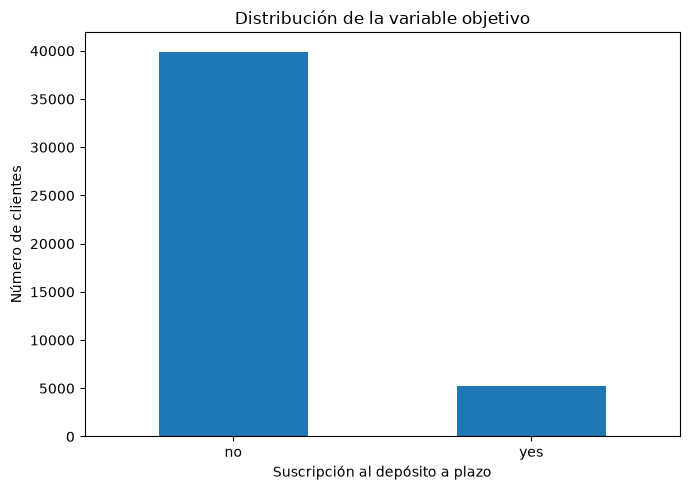

In [7]:
conteo_y = df["y"].value_counts()
porcentaje_y = df["y"].value_counts(normalize=True) * 100

resumen_y = pd.DataFrame({
    "cantidad": conteo_y,
    "porcentaje": porcentaje_y.round(2)
})

display(resumen_y)

plt.figure(figsize=(7, 5))
conteo_y.plot(kind="bar")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Suscripción al depósito a plazo")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Interpretación: desbalance de la variable objetivo
De los 45.211 registros, 5.289 (11,70 %) corresponden a `yes` y 39.922 (88,30 %) a `no`. Predecir siempre `no` alcanzaría una exactitud del 88,30 % sin identificar ninguna suscripción. Durante el modelado se evaluarán precisión, recall, F1, matriz de confusión y la curva precisión-recall; la exactitud aislada no será suficiente. Estas cifras describen la muestra histórica y no una probabilidad garantizada para nuevos clientes.

## Análisis de cada variable

### Análisis de las variables numéricas

Estadísticas descriptivas:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


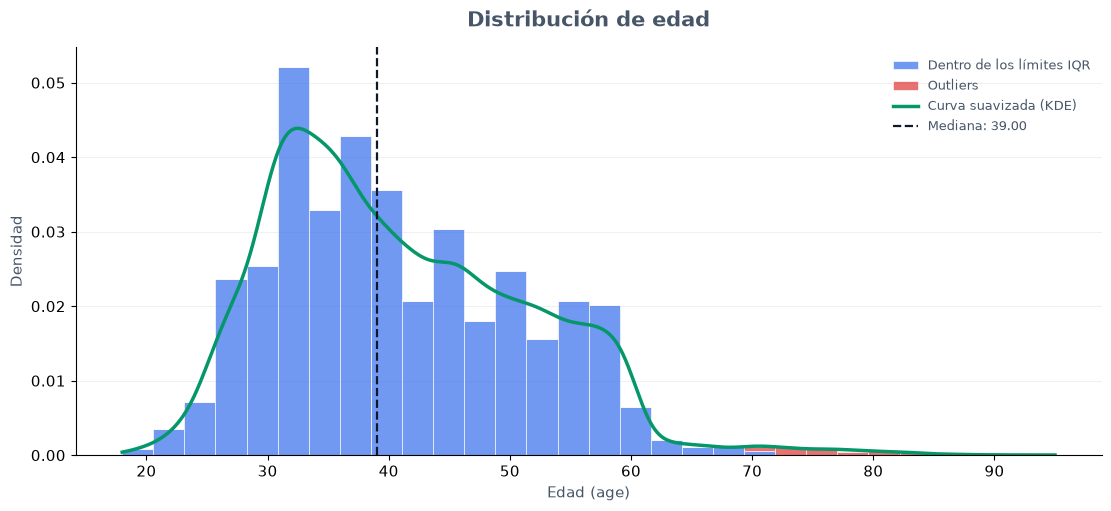

/var/folders/46/9yx1yd2j5879jktms4thrhl40000gn/T/ipykernel_13990/746561608.py:155: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


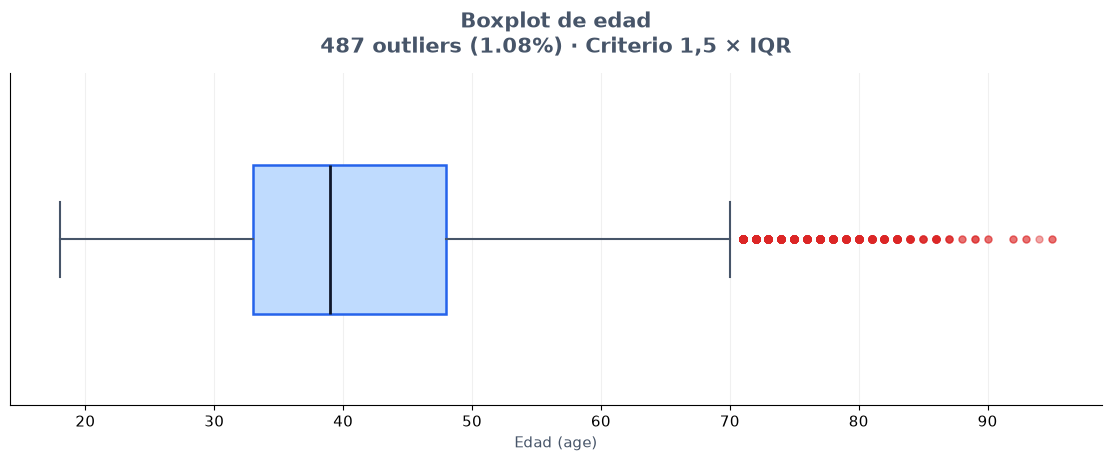

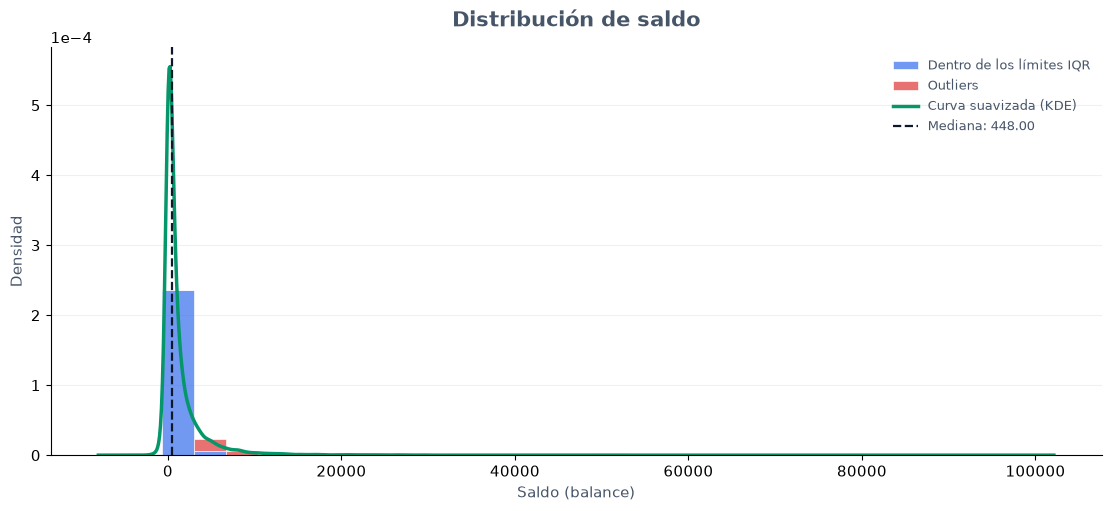

/var/folders/46/9yx1yd2j5879jktms4thrhl40000gn/T/ipykernel_13990/746561608.py:155: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


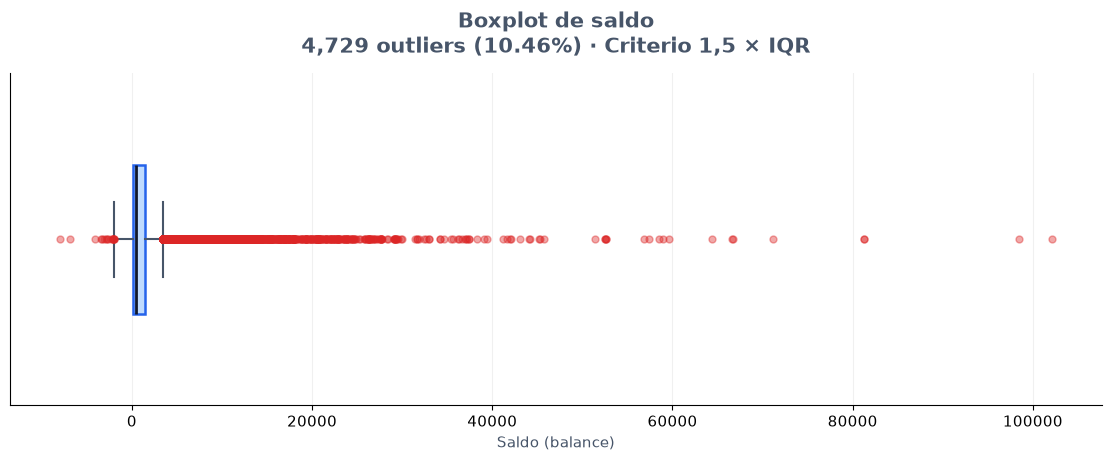

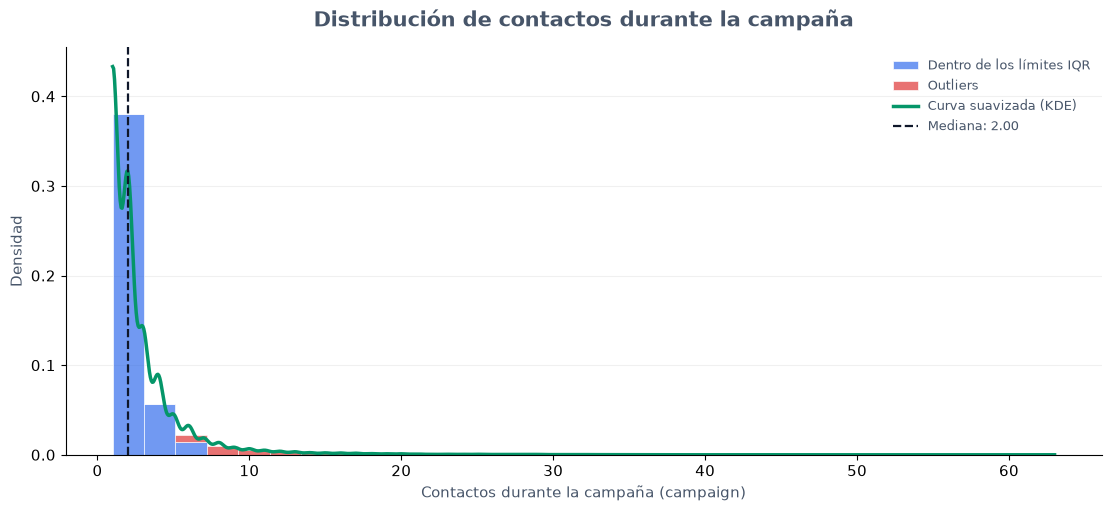

/var/folders/46/9yx1yd2j5879jktms4thrhl40000gn/T/ipykernel_13990/746561608.py:155: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


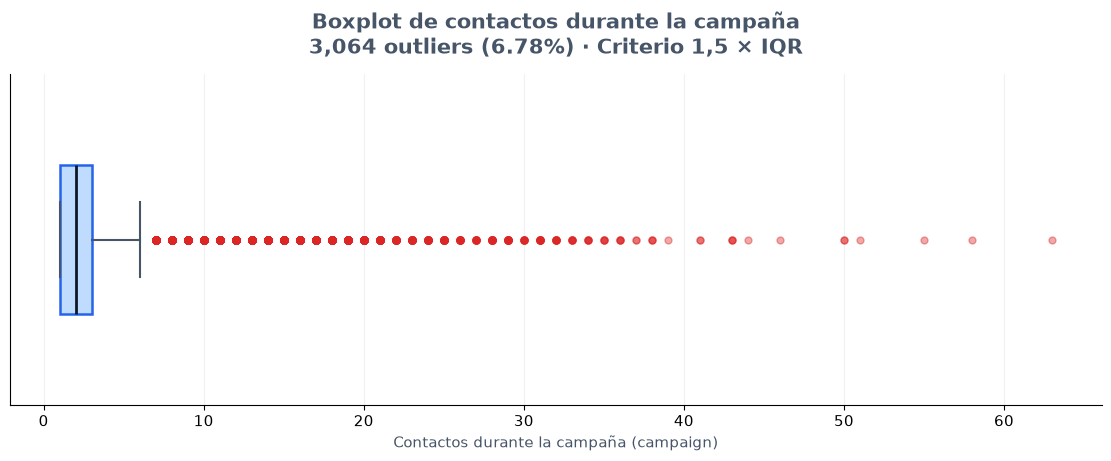

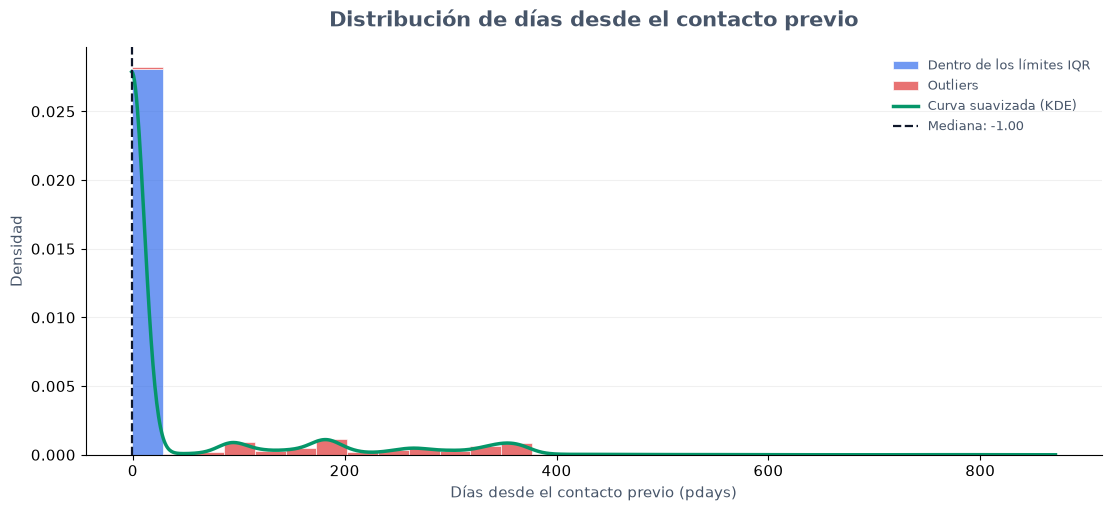

/var/folders/46/9yx1yd2j5879jktms4thrhl40000gn/T/ipykernel_13990/746561608.py:155: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


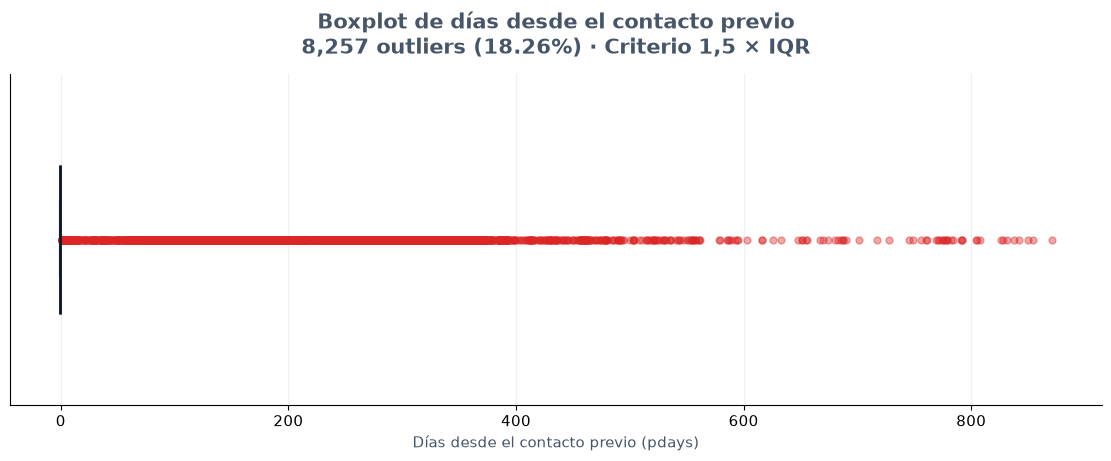

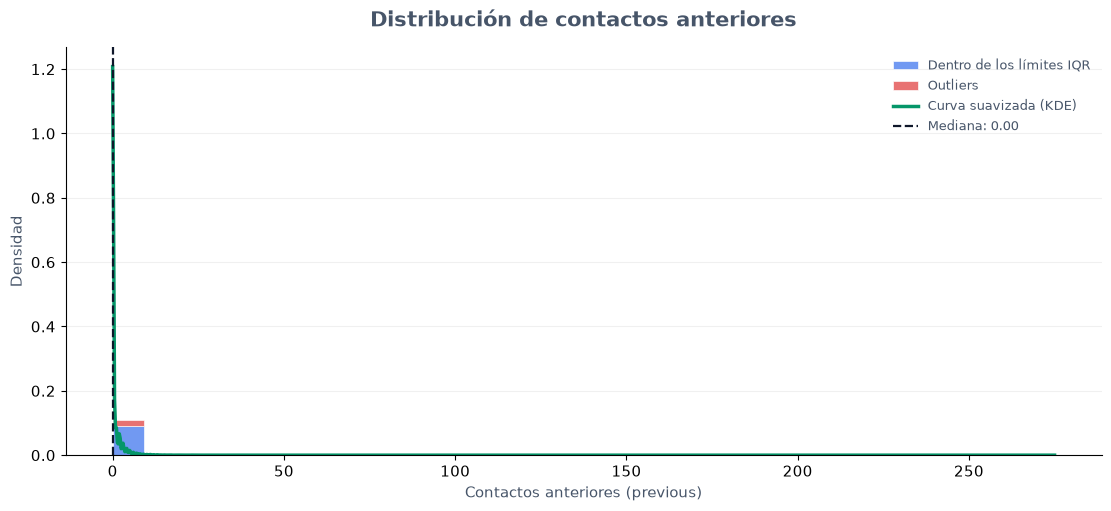

/var/folders/46/9yx1yd2j5879jktms4thrhl40000gn/T/ipykernel_13990/746561608.py:155: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


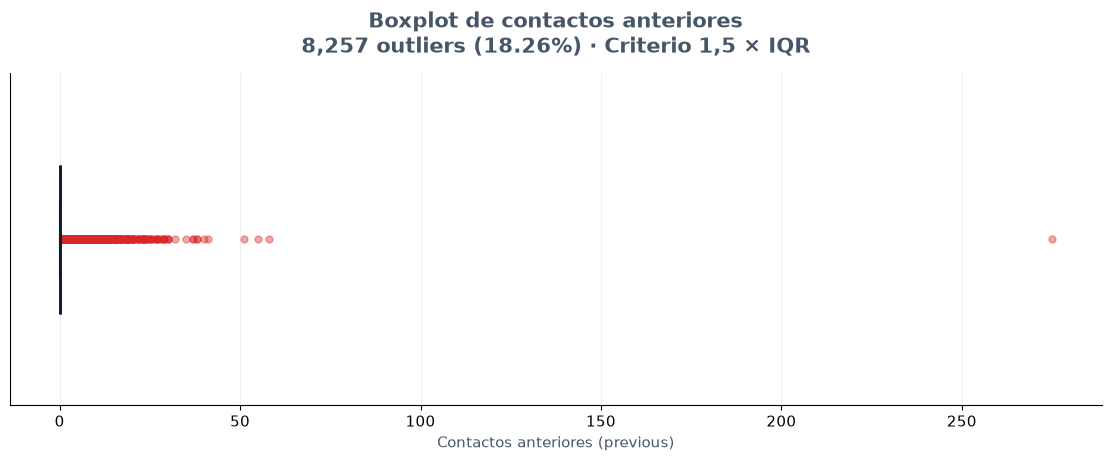

Resumen de valores atípicos:


,Variable,Observaciones,Q1,Q3,IQR,Límite inferior,Límite superior,Outliers,% outliers
0,age,45211,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,45211,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,campaign,45211,1.0,3.0,2.0,-2.0,6.0,3064,6.78
3,pdays,45211,-1.0,-1.0,0.0,-1.0,-1.0,8257,18.26
4,previous,45211,0.0,0.0,0.0,0.0,0.0,8257,18.26


In [8]:
# 1. Estadísticas descriptivas
numericas = df.select_dtypes(include="number")

print("Estadísticas descriptivas:")
display(numericas.describe().T.round(2))

# Variables que vamos a analizar
variables = ["age", "balance", "campaign", "pdays", "previous"]

etiquetas = {
    "age": "Edad",
    "balance": "Saldo",
    "campaign": "Contactos durante la campaña",
    "pdays": "Días desde el contacto previo",
    "previous": "Contactos anteriores"
}

# Colores
AZUL = "#2563EB"
AZUL_CLARO = "#BFDBFE"
ROJO = "#DC2626"
VERDE = "#059669"
GRIS = "#475569"

resumen_outliers = []
outliers_por_variable = {}

estilo = {
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.labelcolor": GRIS,
    "text.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
}

for variable in variables:
    if variable not in df.columns:
        continue

    valores = (
        pd.to_numeric(df[variable], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if valores.empty:
        continue

    nombre = etiquetas.get(variable, variable)

    # 2. Detección de outliers mediante 1,5 × IQR
    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    mascara_outliers = (
        (valores < limite_inferior)
        | (valores > limite_superior)
    )

    atipicos = valores[mascara_outliers]
    porcentaje = len(atipicos) / len(valores) * 100
    mediana = valores.median()

    outliers_por_variable[variable] = (
        atipicos.sort_values().to_frame(name=variable)
    )

    resumen_outliers.append({
        "Variable": variable,
        "Observaciones": len(valores),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Outliers": len(atipicos),
        "% outliers": porcentaje
    })

    with plt.rc_context(estilo):

        # 3. FIGURA INDEPENDIENTE: distribución y curva KDE
        fig, ax = plt.subplots(
            figsize=(11, 5),
            constrained_layout=True
        )

        bordes = np.histogram_bin_edges(valores, bins=30)

        # Densidad para que histograma y KDE usen la misma escala
        ax.hist(
            [valores[~mascara_outliers], atipicos],
            bins=bordes,
            stacked=True,
            density=True,
            color=[AZUL, ROJO],
            alpha=0.65,
            edgecolor="white",
            linewidth=0.7,
            label=["Dentro de los límites IQR", "Outliers"]
        )

        # KDE: requiere al menos dos valores diferentes
        if valores.nunique() > 1:
            kde = gaussian_kde(valores.to_numpy())

            eje_x = np.linspace(
                valores.min(),
                valores.max(),
                1000
            )

            ax.plot(
                eje_x,
                kde(eje_x),
                color=VERDE,
                linewidth=2.5,
                label="Curva suavizada (KDE)"
            )

        ax.axvline(
            mediana,
            color="#0F172A",
            linestyle="--",
            linewidth=1.6,
            label=f"Mediana: {mediana:,.2f}"
        )

        ax.set_title(f"Distribución de {nombre.lower()}", pad=15)
        ax.set_xlabel(f"{nombre} ({variable})")
        ax.set_ylabel("Densidad")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.18)
        ax.legend(frameon=False, fontsize=9)
        ax.ticklabel_format(
            axis="y", style="sci", scilimits=(-3, 3)
        )

        plt.show()

        # 4. Boxplot
        fig, ax = plt.subplots(
            figsize=(11, 4.5),
            constrained_layout=True
        )

        ax.boxplot(
            valores.to_numpy(),
            vert=False,
            widths=0.45,
            whis=1.5,
            patch_artist=True,
            showfliers=True,
            boxprops={
                "facecolor": AZUL_CLARO,
                "edgecolor": AZUL,
                "linewidth": 1.8
            },
            medianprops={
                "color": "#0F172A",
                "linewidth": 2
            },
            whiskerprops={
                "color": GRIS,
                "linewidth": 1.5
            },
            capprops={
                "color": GRIS,
                "linewidth": 1.5
            },
            flierprops={
                "marker": "o",
                "markerfacecolor": ROJO,
                "markeredgecolor": ROJO,
                "markersize": 5,
                "alpha": 0.4
            }
        )

        ax.set_title(
            f"Boxplot de {nombre.lower()}\n"
            f"{len(atipicos):,} outliers "
            f"({porcentaje:.2f}%) · Criterio 1,5 × IQR",
            pad=15
        )

        ax.set_xlabel(f"{nombre} ({variable})")
        ax.set_yticks([])
        ax.set_axisbelow(True)
        ax.grid(axis="x", alpha=0.18)

        plt.show()

# 5. Tabla resumen de outliers
resumen_outliers = pd.DataFrame(resumen_outliers)

print("Resumen de valores atípicos:")
display(resumen_outliers.round(2))

### Interpretación: valores atípicos y códigos especiales
El criterio de 1,5 × IQR identifica 487 registros en `age` (1,08 %), 4.729 en `balance` (10,46 %) y 3.064 en `campaign` (6,78 %). Son señales para revisar las distribuciones, no una justificación automática para eliminar observaciones.

En `pdays`, Q1 = Q3 = -1; en `previous`, Q1 = Q3 = 0. Por tanto, el IQR es cero y los límites colapsan a esos valores. El método marca 8.257 registros (18,26 %) en cada variable, correspondientes a valores distintos de su categoría dominante. `pdays = -1` representa ausencia de contacto en campañas anteriores y `previous = 0` indica cero contactos previos. Los registros restantes no son necesariamente errores ni deben eliminarse por esta etiqueta estadística. Conviene estudiar por separado la presencia de contacto previo y, entre quienes lo tuvieron, la distribución de los días y del número de contactos. Se conservan los datos originales.

### Análisis de las variables categóricas

In [9]:
categoricas = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for variable in categoricas:
    serie = df[variable]
    total = len(serie)

    # Identificar "unknown", ignorando mayúsculas y espacios
    es_unknown = (
        serie.astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .fillna(False)
    )

    # Moda incluyendo "unknown", pero excluyendo valores nulos
    modas_con_unknown = serie.mode(dropna=True)

    # Moda excluyendo tanto "unknown" como los valores nulos
    valores_conocidos = serie[~es_unknown].dropna()
    modas_sin_unknown = valores_conocidos.mode(dropna=True)

    # Frecuencias sobre el total de registros, incluidos los nulos
    tabla = (
        serie.value_counts(dropna=False)
        .rename_axis("Categoría")
        .reset_index(name="Frecuencia absoluta")
    )

    tabla["Frecuencia relativa"] = (
        tabla["Frecuencia absoluta"] / total if total else 0.0
    )

    tabla["Porcentaje (%)"] = (
        tabla["Frecuencia relativa"] * 100
    )

    # Marcar todas las categorías modales si existe empate
    for columna, modas in [
        ("Moda con unknown", modas_con_unknown),
        ("Moda sin unknown", modas_sin_unknown)
    ]:
        if modas.empty:
            tabla[columna] = "No aplica"
        else:
            es_moda = (
                tabla["Categoría"].notna()
                & tabla["Categoría"].isin(modas.tolist())
            )

            tabla[columna] = np.where(es_moda, "Sí", "No")

    # Etiqueta para los nulos, distinta de la categoría "unknown"
    tabla["Categoría"] = (
        tabla["Categoría"]
        .astype("object")
        .where(tabla["Categoría"].notna(), "(Faltante)")
    )

    print(f"\nDistribución de {variable}:")

    display(
        tabla.style.format({
            "Frecuencia absoluta": "{:,.0f}",
            "Frecuencia relativa": "{:.4f}",
            "Porcentaje (%)": "{:.2f}"
        })
    )


Distribución de job:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,blue-collar,"9,732",0.2153,21.53,Sí,Sí
1,management,"9,458",0.2092,20.92,No,No
2,technician,"7,597",0.1680,16.80,No,No
3,admin.,"5,171",0.1144,11.44,No,No
4,services,"4,154",0.0919,9.19,No,No
5,retired,"2,264",0.0501,5.01,No,No
6,self-employed,"1,579",0.0349,3.49,No,No
7,entrepreneur,"1,487",0.0329,3.29,No,No
8,unemployed,"1,303",0.0288,2.88,No,No
9,housemaid,"1,240",0.0274,2.74,No,No



Distribución de marital:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,married,"27,214",0.6019,60.19,Sí,Sí
1,single,"12,790",0.2829,28.29,No,No
2,divorced,"5,207",0.1152,11.52,No,No



Distribución de education:


...

,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,may,"13,766",0.3045,30.45,Sí,Sí
1,jul,"6,895",0.1525,15.25,No,No
2,aug,"6,247",0.1382,13.82,No,No
3,jun,"5,341",0.1181,11.81,No,No
4,nov,"3,970",0.0878,8.78,No,No
5,apr,"2,932",0.0649,6.49,No,No
6,feb,"2,649",0.0586,5.86,No,No
7,jan,"1,403",0.0310,3.10,No,No
8,oct,738,0.0163,1.63,No,No
9,sep,579,0.0128,1.28,No,No



Distribución de poutcome:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,unknown,"36,959",0.8175,81.75,Sí,No
1,failure,"4,901",0.1084,10.84,No,Sí
2,other,"1,840",0.0407,4.07,No,No
3,success,"1,511",0.0334,3.34,No,No



Distribución de y:


,Categoría,Frecuencia absoluta,Frecuencia relativa,Porcentaje (%),Moda con unknown,Moda sin unknown
0,no,"39,922",0.8830,88.30,Sí,Sí
1,yes,"5,289",0.1170,11.70,No,No


### Interpretación: frecuencias y modas
Las frecuencias incluyen los nulos, mientras que las modas se calculan excluyéndolos. Se muestran modas con y sin `unknown` para evitar que una categoría de información no especificada o de antecedentes no conocidos oculte las categorías conocidas. La normalización de espacios y mayúsculas se usa para detectar `unknown`; no recodifica los valores originales ni imputa categorías.


Porcentaje de suscripción por job:


y,no,yes
job,,
student,71.32,28.68
retired,77.21,22.79
unemployed,84.50,15.50
management,86.24,13.76
admin.,87.80,12.20
self-employed,88.16,11.84
unknown,88.19,11.81
technician,88.94,11.06
services,91.12,8.88


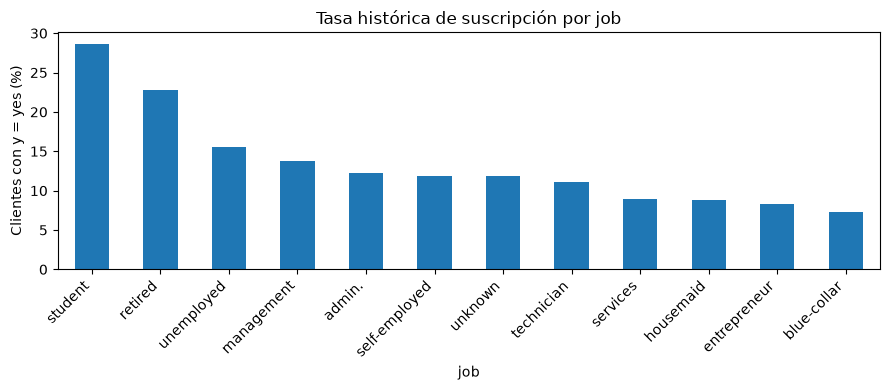


Porcentaje de suscripción por marital:


y,no,yes
marital,,
single,85.05,14.95
divorced,88.05,11.95
married,89.88,10.12


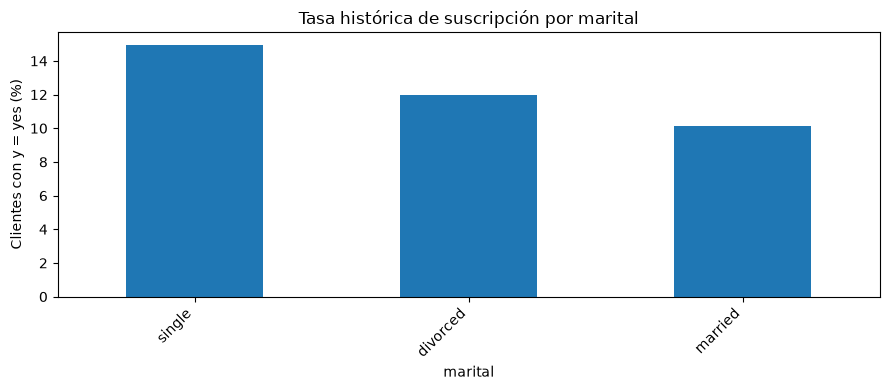


Porcentaje de suscripción por education:


y,no,yes
education,,
tertiary,84.99,15.01
unknown,86.43,13.57
secondary,89.44,10.56
primary,91.37,8.63


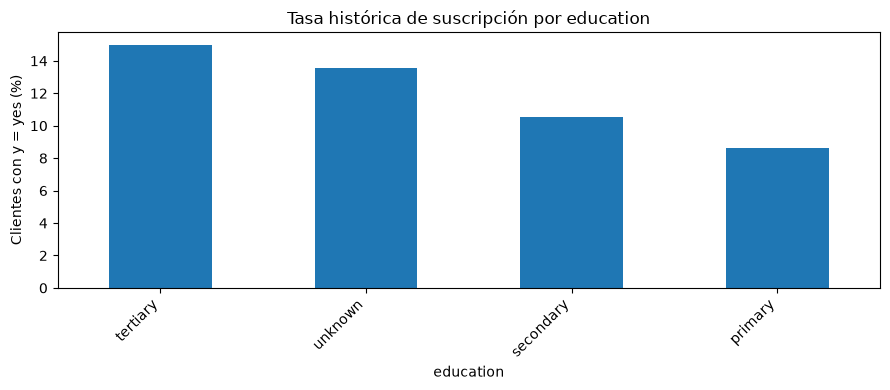


Porcentaje de suscripción por housing:


y,no,yes
housing,,
no,83.3,16.7
yes,92.3,7.7


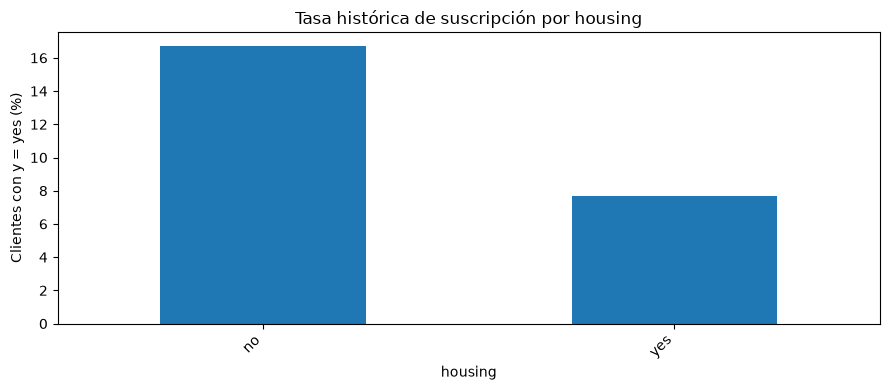


Porcentaje de suscripción por loan:


y,no,yes
loan,,
no,87.34,12.66
yes,93.32,6.68


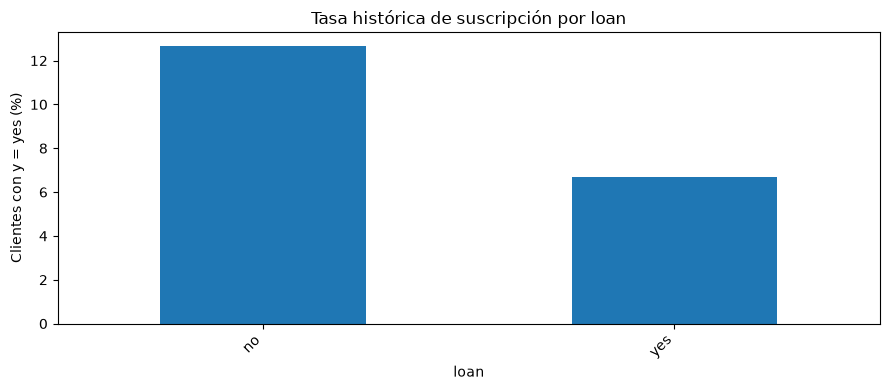


Porcentaje de suscripción por contact:


y,no,yes
contact,,
cellular,85.08,14.92
telephone,86.58,13.42
unknown,95.93,4.07


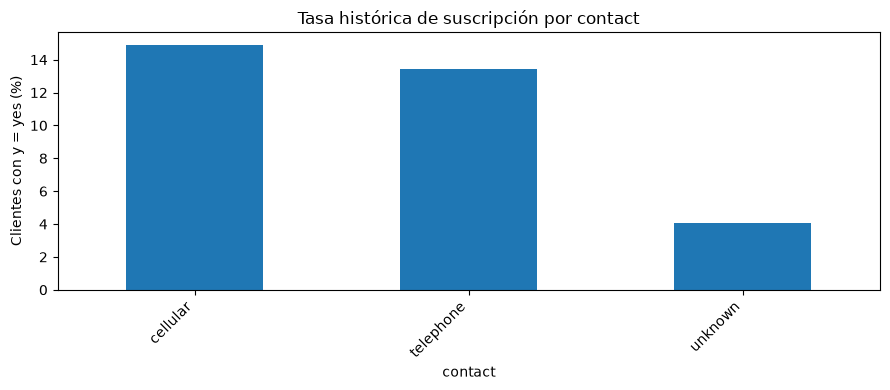


Porcentaje de suscripción por poutcome:


y,no,yes
poutcome,,
success,35.27,64.73
other,83.32,16.68
failure,87.39,12.61
unknown,90.84,9.16


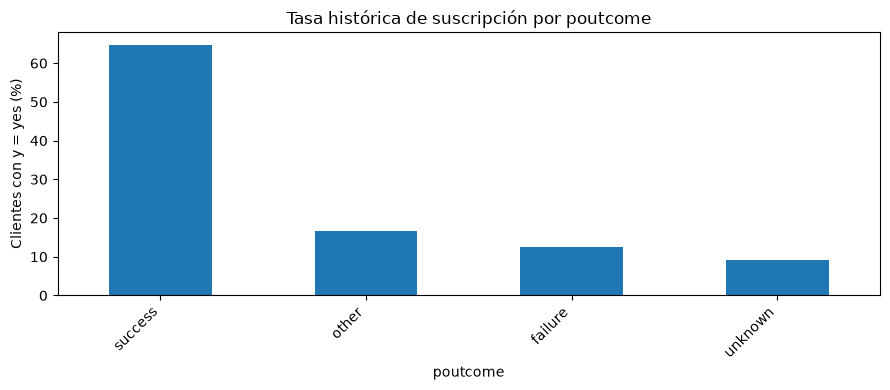

In [10]:
variables_categoricas = [
    "job", "marital", "education",
    "housing", "loan", "contact", "poutcome"
]

for variable in variables_categoricas:
    if variable in df.columns:
        tabla = pd.crosstab(
            df[variable],
            df["y"],
            normalize="index"
        ) * 100

        if "yes" in tabla.columns:
            tabla = tabla.sort_values("yes", ascending=False)

        print(f"\nPorcentaje de suscripción por {variable}:")
        display(tabla.round(2))

        if "yes" in tabla.columns:
            plt.figure(figsize=(9, 4))
            tabla["yes"].plot(kind="bar")
            plt.title(f"Tasa histórica de suscripción por {variable}")
            plt.xlabel(variable)
            plt.ylabel("Clientes con y = yes (%)")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            if variable in {"job", "poutcome"}:
                nombre_figura = {"job": "figura_2_suscripcion_ocupacion.png", "poutcome": "figura_4_suscripcion_campana_anterior.png"}[variable]
                plt.savefig(ruta_figuras / nombre_figura, dpi=180, bbox_inches="tight")
            plt.show()

### Interpretación: asociaciones con la suscripción
Las tasas de suscripción son 28,68 % para `student` y 22,79 % para `retired`, frente al 11,70 % global. Para `poutcome`, son 64,73 % en `success`, 16,68 % en `other`, 12,61 % en `failure` y 9,16 % en `unknown`. Se conserva esta última categoría también en la gráfica. Estas asociaciones no prueban causalidad; el tamaño de cada grupo y la disponibilidad de los antecedentes antes de la predicción deben considerarse al modelar.


Resumen de age según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,40.84,39.0,10.17,18,95
yes,5289,41.67,38.0,13.50,18,95


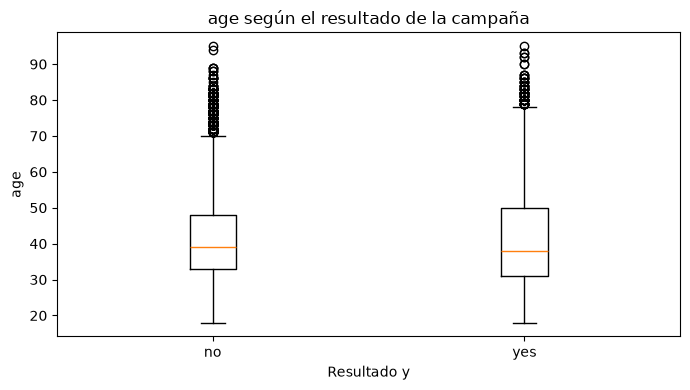


Resumen de balance según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,1303.71,417.0,2974.2,-8019,102127
yes,5289,1804.27,733.0,3501.1,-3058,81204


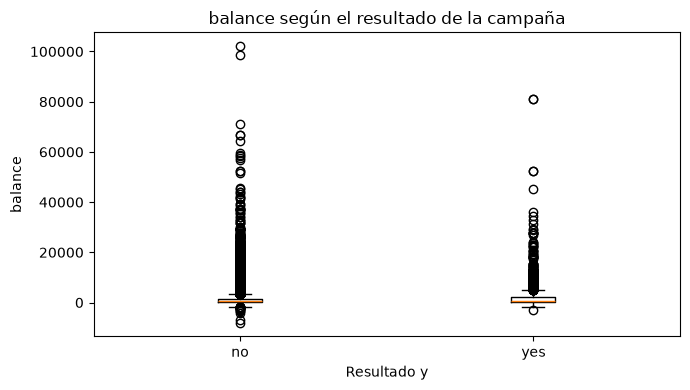


Resumen de campaign según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,2.85,2.0,3.21,1,63
yes,5289,2.14,2.0,1.92,1,32


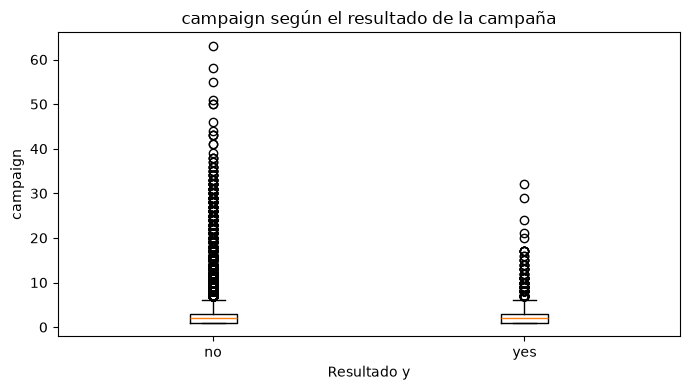


Resumen de previous según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,0.50,0.0,2.26,0,275
yes,5289,1.17,0.0,2.55,0,58


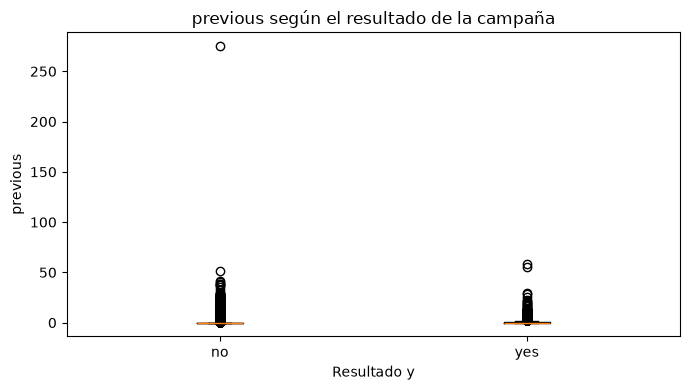


Resumen de duration según y:


,count,mean,median,std,min,max
y,,,,,,
no,39922,221.18,164.0,207.38,0,4918
yes,5289,537.29,426.0,392.53,8,3881


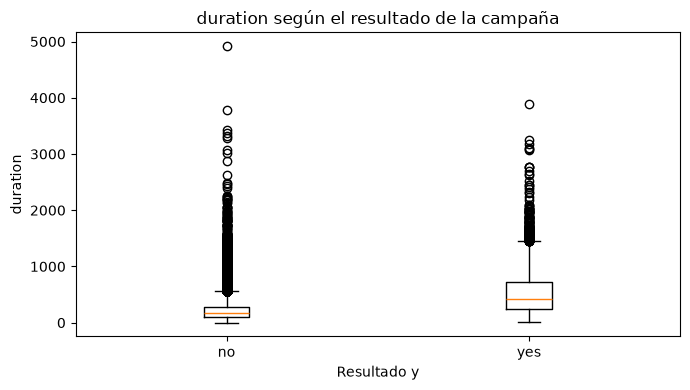

In [11]:
variables_numericas = ["age", "balance", "campaign", "previous", "duration"]

for variable in variables_numericas:
    if variable in df.columns:
        print(f"\nResumen de {variable} según y:")
        display(
            df.groupby("y")[variable]
              .agg(["count", "mean", "median", "std", "min", "max"])
              .round(2)
        )

        grupos = [
            df.loc[df["y"] == clase, variable].dropna()
            for clase in ["no", "yes"]
        ]

        plt.figure(figsize=(7, 4))
        plt.boxplot(grupos, tick_labels=["no", "yes"])
        plt.title(f"{variable} según el resultado de la campaña")
        plt.xlabel("Resultado y")
        plt.ylabel(variable)
        plt.tight_layout()
        if variable == "balance":
            plt.savefig(ruta_figuras / "figura_3_saldo_segun_suscripcion.png", dpi=180, bbox_inches="tight")
        plt.show()

### Interpretación: variables numéricas según el resultado
La edad media es similar entre `no` (40,84) y `yes` (41,67), mientras que el saldo mediano es mayor en `yes` (733 frente a 417). Los extremos del saldo aconsejan evaluar transformaciones o métodos robustos sin asumir que un saldo negativo es un error.

`duration` se presenta exclusivamente para describir el conjunto histórico: no está disponible antes de realizar la llamada y se excluirá de los predictores del modelo de priorización. Las variables de la campaña actual también deben revisarse según el momento exacto en que se realizaría la predicción.

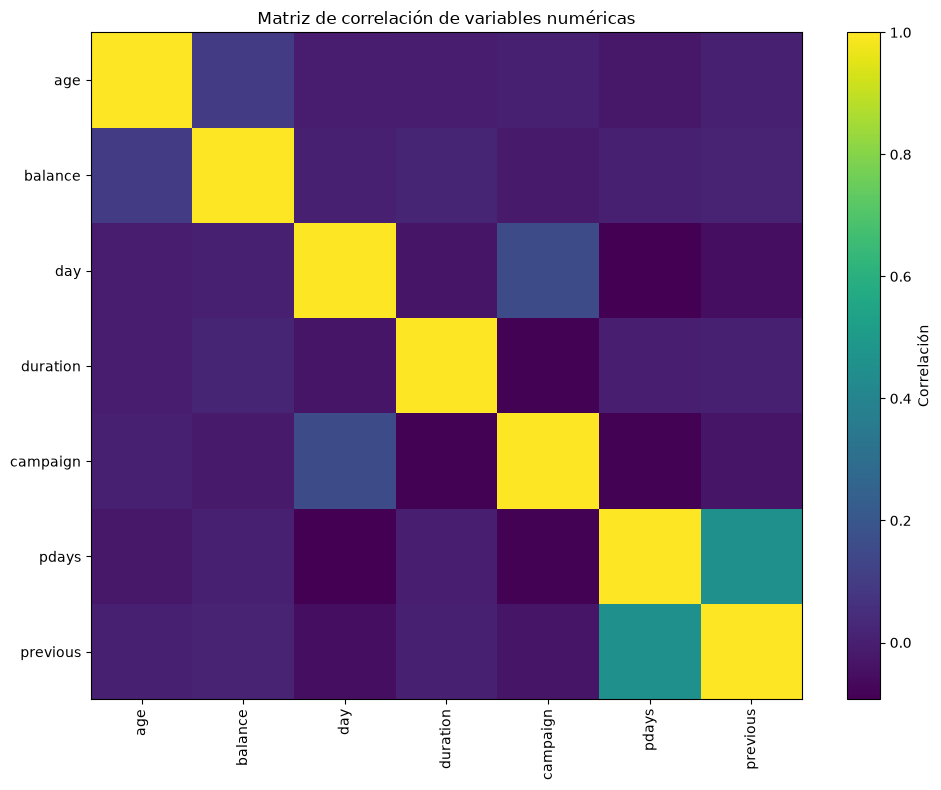

In [12]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect="auto", cmap="viridis")
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

# Diagnóstico de valores faltantes

Se cuentan por separado los NaN y los valores explícitos `unknown`.

In [13]:
total_filas = len(df)

diagnostico_faltantes = pd.DataFrame({
    "variable": df.columns,
    "numero_NaN": df.isna().sum().values,
    "porcentaje_NaN": (
        df.isna().sum().values / total_filas * 100
    ).round(2),
    "numero_unknown": [
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
        .eq("unknown")
        .sum()
        for col in df.columns
    ]
})

diagnostico_faltantes = diagnostico_faltantes.sort_values(
    by=["numero_NaN", "numero_unknown"],
    ascending=False
).reset_index(drop=True)

print("Diagnóstico de valores faltantes por variable")
print(f"Número total de registros: {total_filas:,}")
display(diagnostico_faltantes)


Diagnóstico de valores faltantes por variable
Número total de registros: 45,211


,variable,numero_NaN,porcentaje_NaN,numero_unknown
0,poutcome,0,0.0,36959
1,contact,0,0.0,13020
2,education,0,0.0,1857
3,job,0,0.0,288
4,age,0,0.0,0
5,marital,0,0.0,0
6,default,0,0.0,0
7,balance,0,0.0,0
8,housing,0,0.0,0
9,loan,0,0.0,0


In [14]:
# Comprobaciones de la versión bank-full.csv identificada por el hash DVC.
# Fallan explícitamente si se modifica el archivo, la lectura o los conteos esperados.
assert df.shape == (45211, 17), f"Dimensiones inesperadas: {df.shape}"
assert int(df.isna().sum().sum()) == 0, "Se detectaron valores NaN inesperados"
unknown_esperados = {"poutcome": 36959, "contact": 13020, "education": 1857, "job": 288}
unknown_observados = diagnostico_faltantes.set_index("variable")["numero_unknown"].astype(int).to_dict()
for variable in df.columns:
    assert unknown_observados[variable] == unknown_esperados.get(variable, 0), f"Conteo unknown inesperado en {variable}"
assert df["y"].value_counts(dropna=False).to_dict() == {"no": 39922, "yes": 5289}, "Distribución objetivo inesperada"
assert int(df.duplicated().sum()) == 0, "Se detectaron duplicados exactos inesperados"
print("Validación correcta: 45.211 filas, 17 columnas, 0 NaN, 0 duplicados y conteos de unknown/y esperados.")

Validación correcta: 45.211 filas, 17 columnas, 0 NaN, 0 duplicados y conteos de unknown/y esperados.


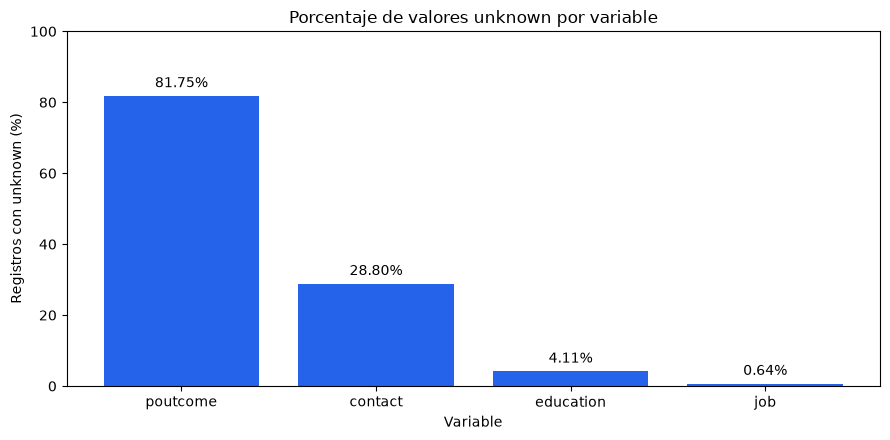

,variable,numero_unknown,porcentaje_unknown
0,poutcome,36959,81.75
1,contact,13020,28.80
2,education,1857,4.11
3,job,288,0.64


In [15]:
# Porcentaje sobre el total de registros; unknown se distingue de NaN.
resumen_unknown = diagnostico_faltantes.loc[
    diagnostico_faltantes["numero_unknown"] > 0, ["variable", "numero_unknown"]
].copy()
resumen_unknown["porcentaje_unknown"] = resumen_unknown["numero_unknown"] / len(df) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(resumen_unknown["variable"], resumen_unknown["porcentaje_unknown"], color="#2563EB")
ax.bar_label(barras, labels=[f"{p:.2f}%" for p in resumen_unknown["porcentaje_unknown"]], padding=4)
ax.set(title="Porcentaje de valores unknown por variable", xlabel="Variable", ylabel="Registros con unknown (%)", ylim=(0, 100))
fig.tight_layout()
fig.savefig(ruta_figuras / "figura_1_porcentaje_unknown.png", dpi=180, bbox_inches="tight")
plt.show()
display(resumen_unknown.round(2))

### Interpretación: calidad y categorías desconocidas
Se verifican cero NaN y cero duplicados exactos. Esto no implica información completamente especificada: `unknown` aparece en `poutcome` (36.959; 81,75 %), `contact` (13.020; 28,80 %), `education` (1.857; 4,11 %) y `job` (288; 0,64 %).

Se conserva `unknown` como categoría explícita; no se eliminan registros ni se imputa automáticamente. En `poutcome` debe distinguirse de la ausencia de contacto previo usando `pdays` y `previous`: sus conteos son próximos pero no idénticos. Los tratamientos definitivos se decidirán durante el modelado y se ajustarán solo con los datos de entrenamiento.

## Revisión específica: contact, education, job y poutcome

In [16]:
variables_prioritarias = ["contact", "education", "job", "poutcome"]

for variable in variables_prioritarias:
    if variable not in df.columns:
        print(f"\nLa variable '{variable}' no está en el DataFrame.")
        continue

    serie = df[variable].astype("string").str.strip()

    total_nan = df[variable].isna().sum()
    total_unknown = serie.str.lower().eq("unknown").sum()

    print(f"\n{'=' * 55}")
    print(f"Variable: {variable}")
    print(f"NaN: {total_nan:,} ({total_nan / len(df) * 100:.2f}%)")
    print(f"Unknown: {total_unknown:,} ({total_unknown / len(df) * 100:.2f}%)")
    print("Distribución de categorías, incluyendo NaN:")

    display(
        df[variable]
        .value_counts(dropna=False)
        .rename_axis("categoria")
        .to_frame("cantidad")
    )


Variable: contact
NaN: 0 (0.00%)
Unknown: 13,020 (28.80%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
cellular,29285
unknown,13020
telephone,2906



Variable: education
NaN: 0 (0.00%)
Unknown: 1,857 (4.11%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
secondary,23202
tertiary,13301
primary,6851
unknown,1857



Variable: job
NaN: 0 (0.00%)
Unknown: 288 (0.64%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
blue-collar,9732
management,9458
technician,7597
admin.,5171
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303



Variable: poutcome
NaN: 0 (0.00%)
Unknown: 36,959 (81.75%)
Distribución de categorías, incluyendo NaN:


,cantidad
categoria,
unknown,36959
failure,4901
other,1840
success,1511


# Validación del diccionario y consistencia de variables

En esta sección se verifica la consistencia del conjunto de datos Bank Marketing, comparando los valores observados con los valores documentados en el diccionario oficial.

Se revisan las categorías de las variables, los tipos de datos y los rangos de las variables numéricas, con el propósito de identificar posibles inconsistencias antes del modelado.

In [17]:
# Categorías documentadas para bank-full.csv
diccionario = {
    "job": {
        "admin.", "blue-collar", "entrepreneur",
        "housemaid", "management", "retired",
        "self-employed", "services", "student",
        "technician", "unemployed", "unknown"
    },
    "marital": {"married", "single", "divorced"},
    "education": {
        "primary", "secondary", "tertiary", "unknown"
    },
    "default": {"yes", "no"},
    "housing": {"yes", "no"},
    "loan": {"yes", "no"},
    "contact": {"cellular", "telephone", "unknown"},
    "month": {
        "jan", "feb", "mar", "apr", "may", "jun",
        "jul", "aug", "sep", "oct", "nov", "dec"
    },
    "poutcome": {
        "success", "failure", "other", "unknown"
    },
    "y": {"yes", "no"}
}

resultados = []

for variable, esperados in diccionario.items():
    if variable not in df.columns:
        resultados.append({
            "variable": variable,
            "valores_observados": "Columna ausente",
            "valores_documentados": sorted(esperados),
            "observaciones": "Revisar columna faltante"
        })
        continue

    observados = set(
        df[variable].dropna().astype(str).unique()
    )

    inesperados = observados - esperados
    no_observados = esperados - observados

    resultados.append({
        "variable": variable,
        "valores_observados": sorted(observados),
        "valores_documentados": sorted(esperados),
        "observaciones": (
            f"Inesperados: {sorted(inesperados)}; "
            f"No observados: {sorted(no_observados)}"
            if inesperados or no_observados
            else "Consistente"
        )
    })

tabla_validacion = pd.DataFrame(resultados)
display(tabla_validacion)

,variable,valores_observados,valores_documentados,observaciones
0,job,"[admin., blue-collar, entrepreneur, housemaid,...","[admin., blue-collar, entrepreneur, housemaid,...",Consistente
1,marital,"[divorced, married, single]","[divorced, married, single]",Consistente
2,education,"[primary, secondary, tertiary, unknown]","[primary, secondary, tertiary, unknown]",Consistente
3,default,"[no, yes]","[no, yes]",Consistente
4,housing,"[no, yes]","[no, yes]",Consistente
5,loan,"[no, yes]","[no, yes]",Consistente
6,contact,"[cellular, telephone, unknown]","[cellular, telephone, unknown]",Consistente
7,month,"[apr, aug, dec, feb, jan, jul, jun, mar, may, ...","[apr, aug, dec, feb, jan, jul, jun, mar, may, ...",Consistente
8,poutcome,"[failure, other, success, unknown]","[failure, other, success, unknown]",Consistente
9,y,"[no, yes]","[no, yes]",Consistente


## Validación de tipos de datos y rangos numéricos

En esta sección se verifica que las variables numéricas del conjunto de datos Bank Marketing tengan tipos de datos adecuados y presenten valores coherentes con su significado.

Se revisan los valores mínimos, máximos y posibles inconsistencias, prestando especial atención a las variables que contienen códigos especiales, como `pdays = -1`, que representa la ausencia de contacto en campañas anteriores.

Los valores extremos se identificarán para su interpretación, sin eliminarlos automáticamente.

In [18]:
# Validación de tipos y rangos de variables numéricas

variables_numericas = [
    "age", "balance", "day",
    "duration", "campaign", "pdays", "previous"
]

resultados_numericos = []

for variable in variables_numericas:
    if variable not in df.columns:
        resultados_numericos.append({
            "variable": variable,
            "tipo_dato": "No existe",
            "minimo": None,
            "maximo": None,
            "observaciones": "Columna ausente"
        })
        continue

    serie = df[variable]
    numerica = pd.to_numeric(serie, errors="coerce")

    observaciones = []

    if not pd.api.types.is_numeric_dtype(serie):
        observaciones.append("Revisar tipo de dato")

    if numerica.isna().sum() > serie.isna().sum():
        observaciones.append("Valores no numéricos")

    if variable == "age" and (numerica < 0).any():
        observaciones.append("Edades negativas")

    if variable == "day" and (
        (numerica < 1) | (numerica > 31)
    ).any():
        observaciones.append("Días fuera de 1-31")

    if variable in ["duration", "campaign", "previous"]:
        if (numerica < 0).any():
            observaciones.append("Valores negativos")

    if variable == "pdays":
        if (numerica < -1).any():
            observaciones.append("Valores menores que -1")

        cantidad_especial = (numerica == -1).sum()
        observaciones.append(
            f"pdays = -1: {cantidad_especial} registros"
        )

    resultados_numericos.append({
        "variable": variable,
        "tipo_dato": str(serie.dtype),
        "minimo": numerica.min(),
        "maximo": numerica.max(),
        "observaciones": (
            "; ".join(observaciones)
            if observaciones else "Sin inconsistencias detectadas"
        )
    })

tabla_numerica = pd.DataFrame(resultados_numericos)
display(tabla_numerica)

,variable,tipo_dato,minimo,maximo,observaciones
0,age,int64,18,95,Sin inconsistencias detectadas
1,balance,int64,-8019,102127,Sin inconsistencias detectadas
2,day,int64,1,31,Sin inconsistencias detectadas
3,duration,int64,0,4918,Sin inconsistencias detectadas
4,campaign,int64,1,63,Sin inconsistencias detectadas
5,pdays,int64,-1,871,pdays = -1: 36954 registros
6,previous,int64,0,275,Sin inconsistencias detectadas


### Hallazgos de la validación de consistencia

La comparación de las 10 variables categóricas evaluadas con el diccionario de referencia no identificó categorías inesperadas ni diferencias de codificación.

Las siete variables numéricas presentan tipos de datos enteros (`int64`) y no se identificaron inconsistencias mediante las reglas básicas de validación de rangos.

Se destacan las siguientes observaciones:

- **age:** las edades se encuentran entre 18 y 95 años.
- **balance:** presenta valores negativos y positivos, entre -8.019 y 102.127. Los saldos negativos no deben considerarse errores automáticamente.
- **day:** los valores se encuentran entre 1 y 31.
- **duration:** presenta duraciones entre 0 y 4.918 segundos. Esta variable debe excluirse del modelo de priorización previo a la llamada.
- **campaign:** registra entre 1 y 63 contactos.
- **pdays:** presenta 36.954 registros con el valor especial -1 (aproximadamente 81,7 %), que debe interpretarse según el diccionario y no tratarse automáticamente como un valor inválido.
- **previous:** registra entre 0 y 275 contactos previos.

En conclusión, las variables evaluadas no presentan inconsistencias evidentes bajo las reglas aplicadas. Sin embargo, esta validación no descarta valores atípicos ni garantiza la calidad completa del conjunto de datos. Se recomienda conservar los valores originales, documentar los códigos especiales y evaluar los extremos durante el análisis exploratorio y la preparación del modelo.